In [1]:
from google.colab import files
import pandas as pd
import io

# הפונקציה תפתח חלון בחירת קבצים במחשב שלך
uploaded = files.upload()

# ודא שהקובץ הועלה בהצלחה
for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving 5000W100mm5Lpm.txt to 5000W100mm5Lpm.txt
User uploaded file "5000W100mm5Lpm.txt" with length 21352 bytes


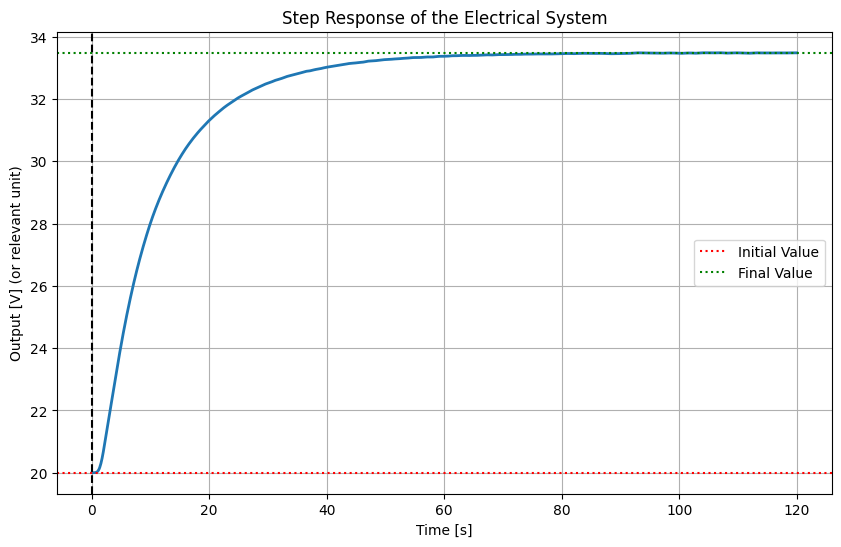

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataframe.
df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])

# Plotting the Step Response
plt.figure(figsize=(10, 6))
plt.plot(df['Time'], df['Output'], linewidth=2)
plt.title('Step Response of the Electrical System')
plt.xlabel('Time [s]')
plt.ylabel('Output [V] (or relevant unit)')
plt.grid(True)
plt.axvline(x=0, color='k', linestyle='--') # Mark the step time if applicable, assuming t=0
plt.axhline(y=df['Output'].iloc[0], color='r', linestyle=':', label='Initial Value')
plt.axhline(y=df['Output'].iloc[-1], color='g', linestyle=':', label='Final Value')
plt.legend()

# Save the plot
plt.savefig('step_response_plot.png')

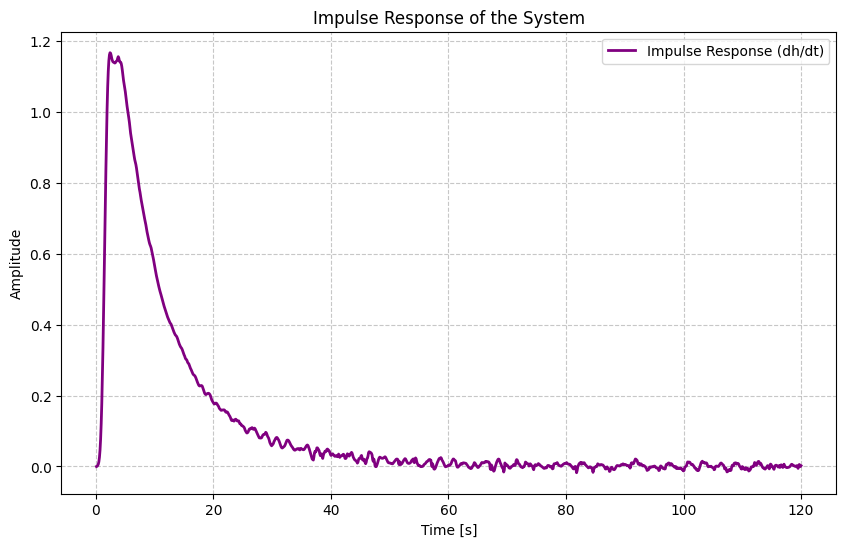

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])

# Calculate the impulse response by differentiating the step response
# h(t) = d(StepResponse)/dt
time = df['Time'].values
output = df['Output'].values

# Calculate derivative using central difference for better accuracy
impulse_response = np.gradient(output, time)

# Plotting the Impulse Response
plt.figure(figsize=(10, 6))
plt.plot(time, impulse_response, label='Impulse Response (dh/dt)', color='purple', linewidth=2)
plt.title('Impulse Response of the System')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Save the plot
plt.savefig('impulse_response_plot.png')

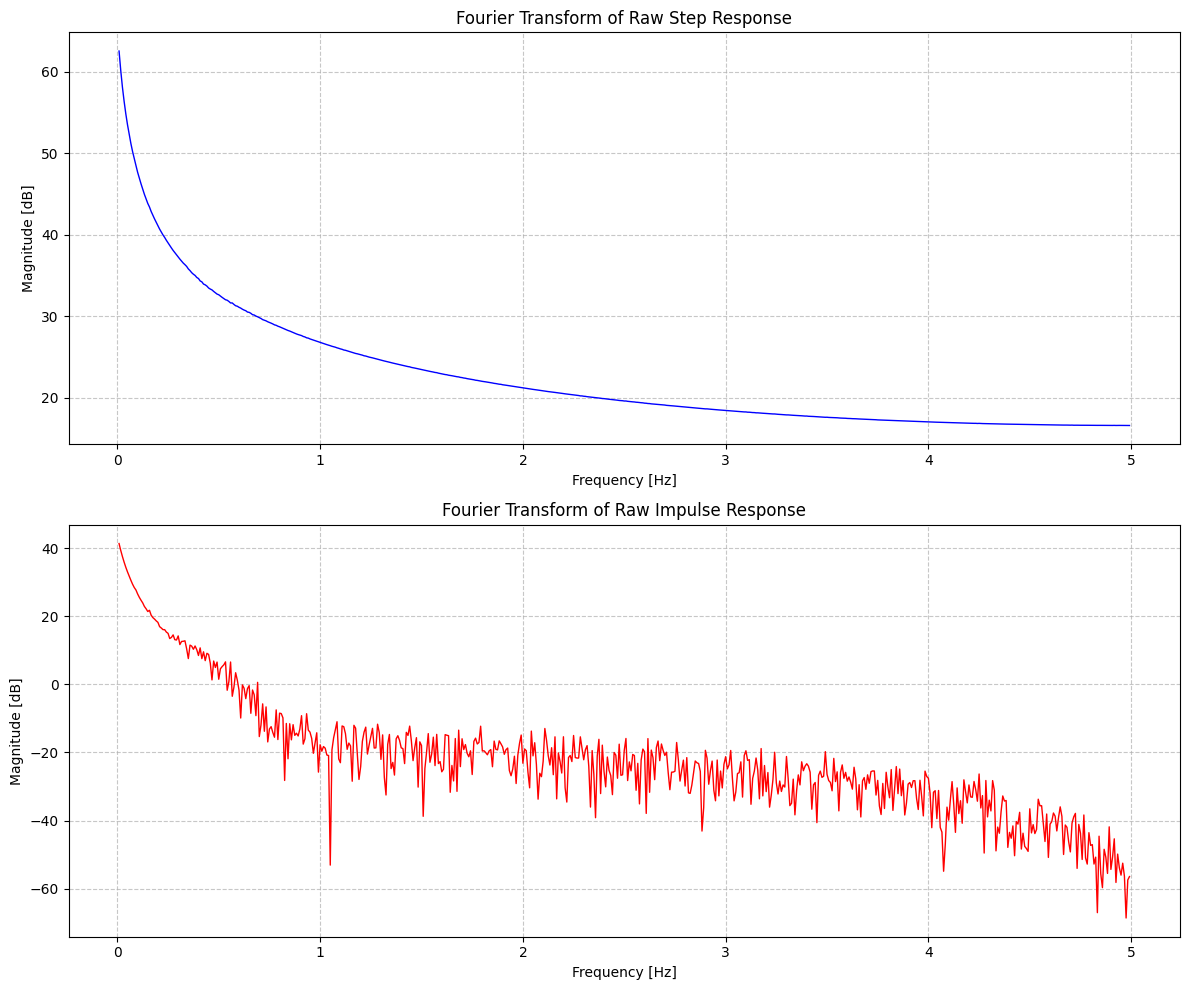

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# קריאת הנתונים
df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
time = df['Time'].values
step_response = df['Output'].values

# מרווח זמן וקצב דגימה
dt = time[1] - time[0]
n = len(time)

# 1. חישוב תגובת ההלם הגולמית (נגזרת ללא החלקה)
impulse_response = np.gradient(step_response, dt)

# 2. חישוב התמרת פוריה לשני האותות
freqs = np.fft.fftfreq(n, dt)
fft_step = np.fft.fft(step_response)
fft_impulse = np.fft.fft(impulse_response)

# סינון תדרים חיוביים בלבד להצגה
pos_mask = freqs > 0
freqs_pos = freqs[pos_mask]
mag_step = np.abs(fft_step[pos_mask])
mag_impulse = np.abs(fft_impulse[pos_mask])

# === המרה לדציבלים (dB) ===
# שימוש ב- np.maximum כדי למנוע שגיאת חלוקה באפס (log(0))
mag_step_db = 20 * np.log10(np.maximum(mag_step, 1e-10))
mag_impulse_db = 20 * np.log10(np.maximum(mag_impulse, 1e-10))

# 3. יצירת הגרפים
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# גרף עליון: התמרת פוריה של תגובת המדרגה הגולמית
ax1.plot(freqs_pos, mag_step_db, color='blue', linewidth=1)
ax1.set_title('Fourier Transform of Raw Step Response')
ax1.set_xlabel('Frequency [Hz]')
ax1.set_ylabel('Magnitude [dB]')
# שים לב: הורדנו את set_yscale('log') כי ה-dB כבר עושה את העבודה!
ax1.grid(True, which="both", ls="--", alpha=0.7)

# גרף תחתון: התמרת פוריה של תגובת ההלם הגולמית
ax2.plot(freqs_pos, mag_impulse_db, color='red', linewidth=1)
ax2.set_title('Fourier Transform of Raw Impulse Response')
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel('Magnitude [dB]')
ax2.grid(True, which="both", ls="--", alpha=0.7)

plt.tight_layout()
plt.savefig('raw_fft_plots_db.png')
plt.show()

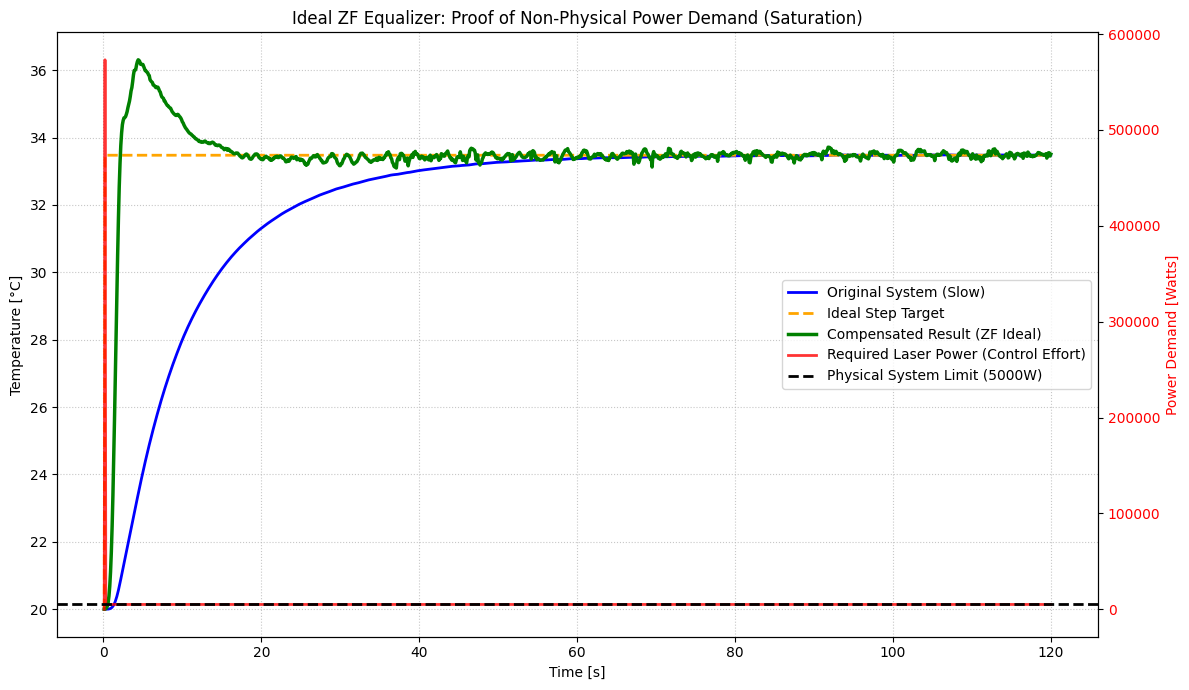

Max Required Power (The Spike): 573088 Watts
Physical Power Limit: 5000.0 Watts
Overload Factor: 114.6x


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import lfilter, cont2discrete

# 1. טעינת הנתונים
df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
t = df['Time'].values
y = df['Output'].values

y_start = y[0]
y_shifted = y - y_start
dt = t[1] - t[0]

# 2. בניית מודל למערכת (System Identification)
def first_order_response(t, K, tau):
    return K * (1 - np.exp(-t / tau))

p0 = [y_shifted[-1], 20.0]
params, _ = curve_fit(first_order_response, t - t[0], y_shifted, p0=p0)
K_est, tau_est = params

# 3. תכנון האקוולייזר (ZF Equalizer Ideal)
sys_c = ([K_est], [tau_est, 1])
sys_d = cont2discrete(sys_c, dt, method='zoh')
num_sys, den_sys = sys_d[0][0], sys_d[1]

num_eq = den_sys
den_eq = num_sys if num_sys[0] != 0 else num_sys[1:]

# 4. חישוב העקומות
# א. יעד המדרגה האידיאלי (ההפרש בטמפרטורה לאקוולייזר)
step_ideal = np.ones_like(t) * K_est
step_ideal[0] = 0

# === הוספה: יעד המדרגה לשרטוט על גרף הטמפרטורה ===
step_target_plot = np.ones_like(t) * (y_start + K_est)
step_target_plot[0] = y_start # הדגימה הראשונה למטה כדי להראות את הקפיצה
# =================================================

# ב. מאמץ הבקרה - המרה להספק אמיתי בוואטים (Watts)!
# אקוולייזר מקבל מדרגה (K_est). ההגבר שלו ב-DC הוא 1/K_est.
# לכן ב-Steady State המוצא שלו הוא 1.
# אנחנו יודעים שהמצב המתמיד בניסוי מקביל ל-5000 וואט. לכן נכפיל ב-5000.
laser_power_step = 5000.0 # [Watts]
control_effort_raw = lfilter(num_eq, den_eq, step_ideal)
control_effort_watts = control_effort_raw * laser_power_step

# ג. התוצאה המפוצה (על האות האמיתי בצלזיוס)
compensated_raw = lfilter(num_eq, den_eq, y_shifted)
compensated_result = compensated_raw * K_est + y_start

# 5. ציור הגרפים
fig, ax1 = plt.subplots(figsize=(12, 7))

# ציר Y ראשון (שמאלי): טמפרטורה (המערכת, המדרגה והתוצאה)
ax1.plot(t, y, label='Original System (Slow)', linewidth=2, color='blue')
# === הוספה: ציור המדרגה האידיאלית ===
ax1.plot(t, step_target_plot, label='Ideal Step Target', linestyle='--', color='orange', linewidth=2)
ax1.plot(t, compensated_result, label='Compensated Result (ZF Ideal)', linewidth=2.5, color='green')
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Temperature [°C]', color='black')
ax1.grid(True, linestyle=':', alpha=0.7)

# ציר Y שני (ימני): מאמץ הבקרה בהספק חשמלי/לייזר (Watts)
ax2 = ax1.twinx()
ax2.plot(t, control_effort_watts, label='Required Laser Power (Control Effort)', color='red', linestyle='-', linewidth=2, alpha=0.8)

# נוסיף קו המראה את המגבלה הפיזיקלית של החומרה שלכם (5000W)
ax2.axhline(laser_power_step, color='black', linestyle='--', linewidth=2, label='Physical System Limit (5000W)')

ax2.set_ylabel('Power Demand [Watts]', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# הוספת כותרות ומקרא
plt.title('Ideal ZF Equalizer: Proof of Non-Physical Power Demand (Saturation)')
fig.tight_layout()
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')

plt.show()

# הדפסת המספרים המדהימים האלו לקונסולה כדי שתוכל לרשום בדוח
print(f"Max Required Power (The Spike): {np.max(control_effort_watts):.0f} Watts")
print(f"Physical Power Limit: {laser_power_step} Watts")
print(f"Overload Factor: {np.max(control_effort_watts)/laser_power_step:.1f}x")

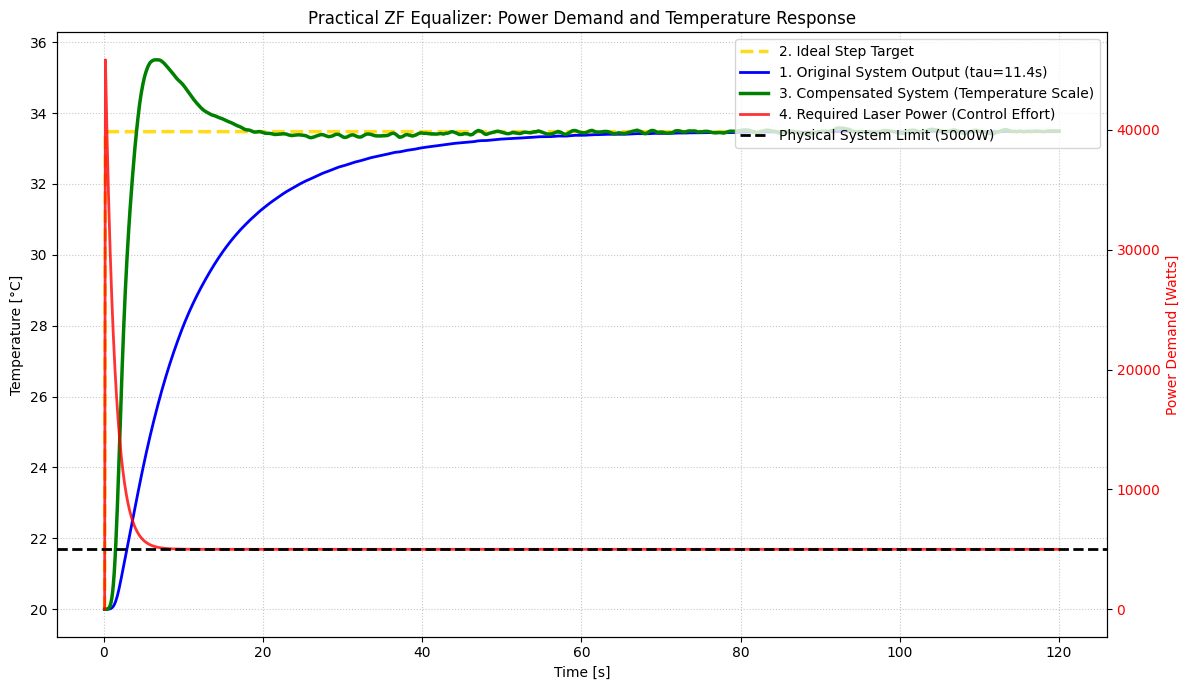

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import lfilter, cont2discrete

# --- 1. טעינת הנתונים והכנה ---
try:
    df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
    t = df['Time'].values
    y = df['Output'].values
except FileNotFoundError:
    print("קובץ הנתונים לא נמצא.")
    exit()

y_start = y[0]
y_shifted = y - y_start
t_shifted = t - t[0]
dt = t[1] - t[0]

# --- 2. בניית מודל למערכת (System Identification) ---
def first_order_response(t, K, tau):
    return K * (1 - np.exp(-t / tau))

p0 = [np.max(y_shifted), 15.0]
params, _ = curve_fit(first_order_response, t_shifted, y_shifted, p0=p0)
K_est, tau_est = params

# --- 3. תכנון האקוולייזר הפיזיקלי (Practical ZF Equalizer) ---
tau_filter = 1.2

# W(s) = (tau_est * s + 1) / (tau_filter * s + 1)
num_c = [tau_est, 1]
den_c = [tau_filter, 1]

# המרה למישור הבדיד (Z)
sys_d = cont2discrete((num_c, den_c), dt, method='bilinear')
b_zf, a_zf = sys_d[0][0], sys_d[1]

# --- 4. חישוב העקומות ---

# עקומה 1: המקורית קיימת כבר כ-y

# עקומה 2: יעד המדרגה האידיאלי
step_ideal = np.ones_like(t) * (y_start + K_est)
step_ideal[0] = y_start

# עקומה 3: התוצאה המפוצה (Temperature Scale)
compensated_physical = lfilter(b_zf, a_zf, y_shifted) + y_start

# עקומה 4: תגובת האקוולייזר עצמו (Control Effort) -> המרה לוואטים!
step_input_shifted = np.ones_like(t) * K_est
step_input_shifted[0] = 0

# הפלט של האקוולייזר הוא ב"מעלות שוות ערך"
eq_response_shifted = lfilter(b_zf, a_zf, step_input_shifted)

# נמיר את זה לוואטים: K_est מעלות שוות ל-5000 וואט
laser_power_step = 5000.0 # [Watts]
control_effort_watts = eq_response_shifted * (laser_power_step / K_est)

# --- 5. ציור הגרף עם שני צירים ---
fig, ax1 = plt.subplots(figsize=(12, 7))
ax1.plot(t, step_ideal, label='2. Ideal Step Target', linestyle='--', color='gold', linewidth=2.5, alpha=0.9)

# ציר שמאלי: טמפרטורה
ax1.plot(t, y, label=f'1. Original System Output (tau={tau_est:.1f}s)', linewidth=2, color='blue')

# --- הוספת המדרגה האידיאלית כאן ---
#ax1.plot(t, step_ideal, label='2. Ideal Step Target', linestyle='--', color='black', linewidth=2, alpha=0.8)
# ----------------------------------

ax1.plot(t, compensated_physical, label='3. Compensated System (Temperature Scale)', linewidth=2.5, color='green')
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Temperature [°C]', color='black')
ax1.grid(True, linestyle=':', alpha=0.7)

# ציר Y שני (ימני): מאמץ הבקרה בהספק חשמלי/לייזר (Watts)
ax2 = ax1.twinx()
ax2.plot(t, control_effort_watts, label='4. Required Laser Power (Control Effort)', color='red', linestyle='-', linewidth=2, alpha=0.8)
ax2.axhline(laser_power_step, color='black', linestyle='--', linewidth=2, label='Physical System Limit (5000W)')
ax2.set_ylabel('Power Demand [Watts]', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# הוספת כותרות ומקרא
plt.title('Practical ZF Equalizer: Power Demand and Temperature Response')
fig.tight_layout()
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.show()

System Parameters: Gain (K)=13.47, Time Constant (tau)=11.41s


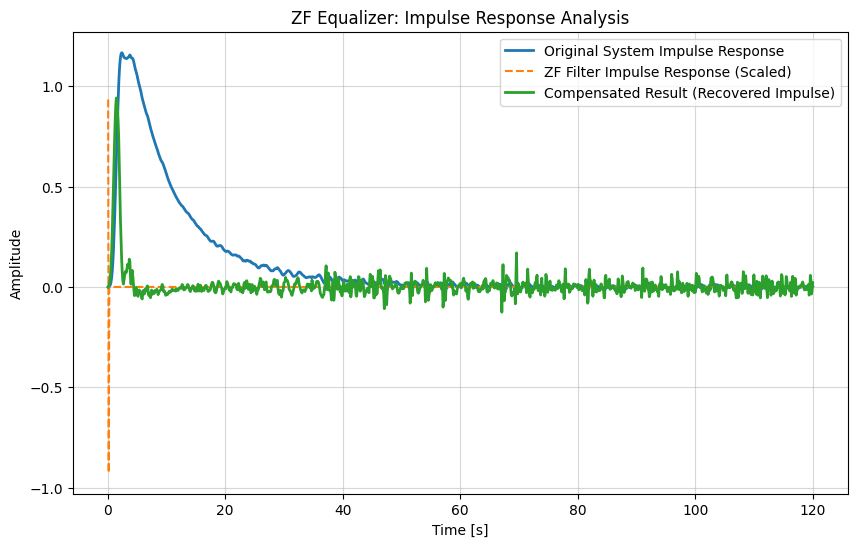

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import lfilter, cont2discrete

# 1. טעינת הנתונים
# וודא שהקובץ נמצא בתיקייה הנכונה
df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
t = df['Time'].values
y = df['Output'].values

# עיבוד מקדים: הזזה להתחלה באפס (מערכת LTI מגיבה לשינוי ביחס לנקודת העבודה)
y_shifted = y - y[0]
dt = t[1] - t[0]

# 2. זיהוי מערכת (System Identification)
# התאמת מודל מסדר ראשון (PT1) לנתונים כדי לקבל פרמטרים נקיים לתכנון
def pt1_func(t, K, tau):
    return K * (1 - np.exp(-(t - t[0])/tau))

# ניחוש התחלתי לפרמטרים (הגבר וקבוע זמן)
p0 = [y_shifted[-1], 20.0]
popt, _ = curve_fit(pt1_func, t, y_shifted, p0=p0)
K_est, tau_est = popt
print(f"System Parameters: Gain (K)={K_est:.2f}, Time Constant (tau)={tau_est:.2f}s")

# 3. תכנון האקוולייזר (ZF Equalizer Design)
# המרת המודל הרציף למודל בדיד (ZOH Discretization)
# H(z) = B(z) / A(z)
sys_c = ([K_est], [tau_est, 1])
sys_d = cont2discrete(sys_c, dt, method='zoh')
num_sys, den_sys = sys_d[0][0], sys_d[1]

# האקוולייזר הוא ההופכי של המערכת: E(z) = 1 / H(z) = A(z) / B(z)
# טיפול בעיכוב: המקדם הראשון במונה של המערכת הוא 0 (בגלל שאין תגובה מיידית),
# לכן אנו לוקחים את המקדמים החל מהאיבר השני כדי לא לחלק באפס.
num_sys_nonzero = num_sys if num_sys[0] != 0 else num_sys[1:]

# מקדמי האקוולייזר (הופכים מונה ומכנה)
num_eq = den_sys
den_eq = num_sys_nonzero

# 4. חישוב העקומות לגרף (Impulse Responses)

# עקומה 1: תגובת ההלם המקורית של המערכת (נגזרת של המדרגה שנמדדה)
orig_impulse = np.gradient(y_shifted, dt)

# עקומה 2: תגובת ההלם של המסנן עצמו (מה המסנן עושה לפולס יחידה)
impulse_input_discrete = np.zeros_like(t)
impulse_input_discrete[0] = 1.0 # פולס יחידה בדיד
zf_impulse_response = lfilter(num_eq, den_eq, impulse_input_discrete)

# עקומה 3: התוצאה המפוצה (שיחזור הפולס המקורי)
# מעבירים את תגובת המערכת המקורית דרך המסנן המתקן
compensated_impulse = lfilter(num_eq, den_eq, orig_impulse)

# 5. נרמול להצגה גרפית
# תגובת המסנן היא חזקה מאוד (אמפליטודה גבוהה), ננרמל אותה כדי שתוצג יפה בגרף ליד האותות האחרים
scale_factor_zf = np.max(orig_impulse) / np.max(np.abs(zf_impulse_response)) * 0.8
zf_impulse_vis = zf_impulse_response * scale_factor_zf

# 6. שרטוט הגרף
plt.figure(figsize=(10, 6))

plt.plot(t, orig_impulse, label='Original System Impulse Response', linewidth=2)
plt.plot(t, zf_impulse_vis, label='ZF Filter Impulse Response (Scaled)', linestyle='--')
plt.plot(t, compensated_impulse, label='Compensated Result (Recovered Impulse)', linewidth=2)

plt.title('ZF Equalizer: Impulse Response Analysis')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

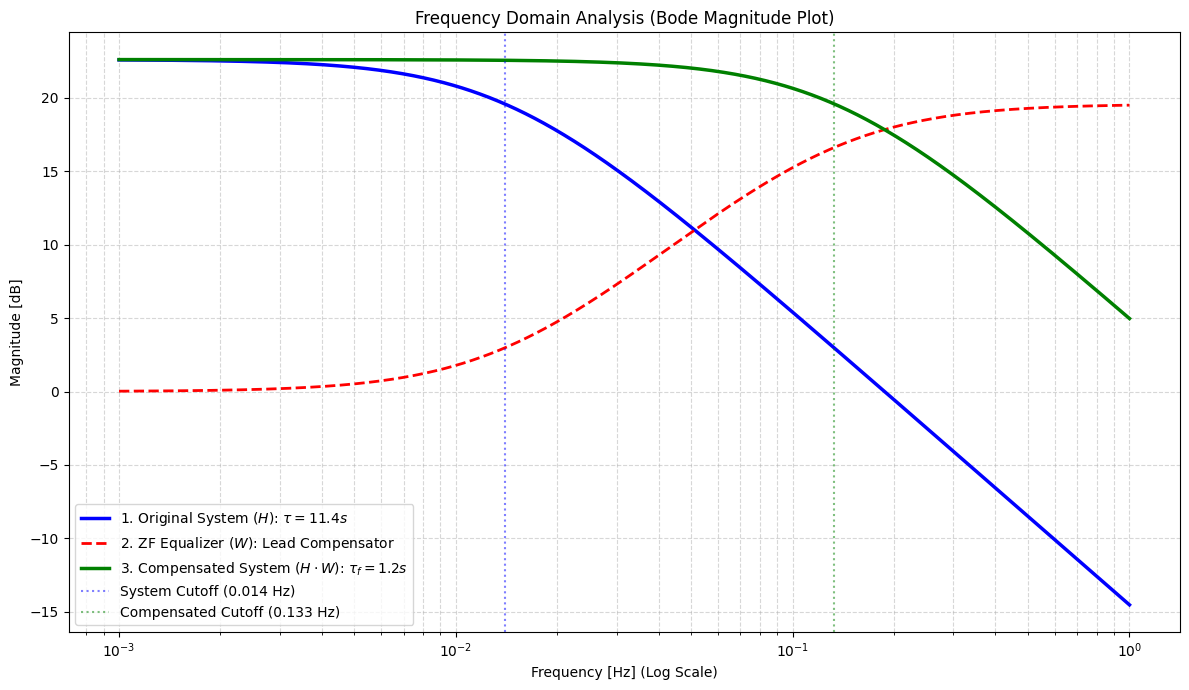

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- 1. טעינת הנתונים וזיהוי מערכת (כמו קודם) ---
df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
t = df['Time'].values
y = df['Output'].values

y_shifted = y - y[0]
t_shifted = t - t[0]

def pt1_func(t, K, tau):
    return K * (1 - np.exp(-t / tau))

popt, _ = curve_fit(pt1_func, t_shifted, y_shifted, p0=[np.max(y_shifted), 15.0])
K_est, tau_est = popt
tau_filter = 1.2 # המגבלה הפיזיקלית של האקוולייזר שהגדרנו

# --- 2. מעבר למישור התדר (Laplace / Fourier) ---
# ניצור ציר תדרים רחב בסקאלה לוגריתמית (מ-0.001 הרץ ועד 1 הרץ)
# במערכות תרמיות איטיות, התדרים החשובים הם מאוד נמוכים.
f = np.logspace(-3, 0, 1000)
w = 2 * np.pi * f
s = 1j * w # המרה ממישור s למישור התדר ההרמוני (s = jw)

# --- 3. חישוב פונקציות התמסורת בתדר ---

# א. המערכת המקורית (Low Pass Filter)
# H(s) = K / (tau * s + 1)
H_freq = K_est / (tau_est * s + 1)
H_mag_dB = 20 * np.log10(np.abs(H_freq))

# ב. האקוולייזר (Lead Compensator / High Pass Filter)
# W(s) = (tau * s + 1) / (tau_filter * s + 1)
W_freq = (tau_est * s + 1) / (tau_filter * s + 1)
W_mag_dB = 20 * np.log10(np.abs(W_freq))

# ג. המערכת המפוצה השלמה (המכפלה שלהם)
# Comp(s) = H(s) * W(s) = K / (tau_filter * s + 1)
Comp_freq = H_freq * W_freq
Comp_mag_dB = 20 * np.log10(np.abs(Comp_freq))

# --- 4. שרטוט הגרף (Bode Magnitude Plot) ---
plt.figure(figsize=(12, 7))

# נשתמש בציר X לוגריתמי (semilogx) כפי שנהוג בעיבוד אותות
plt.semilogx(f, H_mag_dB, label=f'1. Original System ($H$): $\\tau={tau_est:.1f}s$', linewidth=2.5, color='blue')
plt.semilogx(f, W_mag_dB, label=f'2. ZF Equalizer ($W$): Lead Compensator', linestyle='--', color='red', linewidth=2)
plt.semilogx(f, Comp_mag_dB, label=f'3. Compensated System ($H \\cdot W$): $\\tau_f={tau_filter:.1f}s$', linewidth=2.5, color='green')

# סימון תדרי הברך (Cutoff Frequencies) להמחשה הנדסית
fc_system = 1 / (2 * np.pi * tau_est)
fc_comp = 1 / (2 * np.pi * tau_filter)
plt.axvline(fc_system, color='blue', linestyle=':', alpha=0.5, label=f'System Cutoff ({fc_system:.3f} Hz)')
plt.axvline(fc_comp, color='green', linestyle=':', alpha=0.5, label=f'Compensated Cutoff ({fc_comp:.3f} Hz)')

plt.title('Frequency Domain Analysis (Bode Magnitude Plot)')
plt.xlabel('Frequency [Hz] (Log Scale)')
plt.ylabel('Magnitude [dB]')
plt.legend(loc='lower left')
plt.grid(True, which="both", ls="--", alpha=0.5) # רשת כפולה לגרף לוגריתמי
plt.tight_layout()

plt.savefig('bode_plot_equalizer.png', dpi=300)
plt.show()

System Parameters: K = 13.47, tau = 11.41 sec


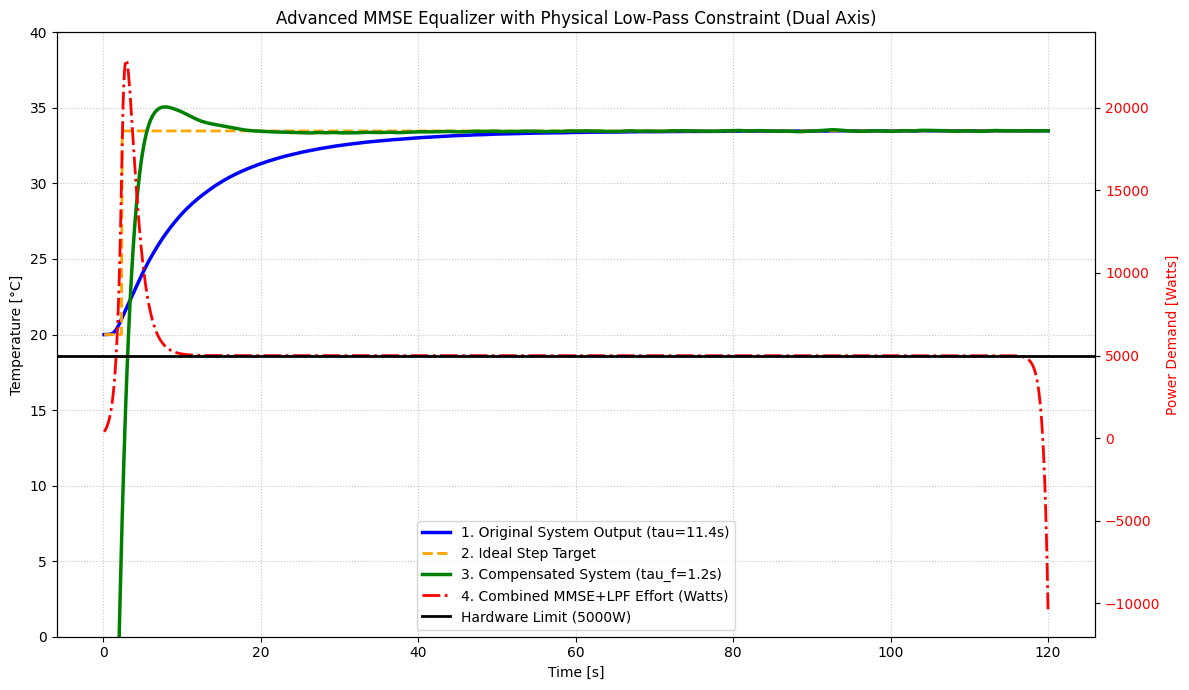

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- 1. טעינת הנתונים והכנה ---
try:
    df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
    t = df['Time'].values
    y = df['Output'].values
except FileNotFoundError:
    print("קובץ הנתונים לא נמצא. משתמש בנתונים סינתטיים להדגמה.")
    t = np.arange(0, 120, 0.1)
    y = np.ones_like(t) * 20.0
    y[t >= 20] += 13.5 * (1 - np.exp(-(t[t >= 20] - 20) / 11.4))
    y += np.random.normal(0, 0.1, len(t))

y_start = y[0]
y_shifted = y - y_start
t_shifted = t - t[0]
dt = t[1] - t[0]
N = len(y)

# --- 2. בניית מודל למערכת (System Identification) ---
def first_order_response(t, K, tau):
    return K * (1 - np.exp(-t / tau))

p0 = [np.max(y_shifted), 15.0]
params, _ = curve_fit(first_order_response, t_shifted, y_shifted, p0=p0)
K_est, tau_est = params
print(f"System Parameters: K = {K_est:.2f}, tau = {tau_est:.2f} sec")

# --- 3. תכנון האקוולייזר (MMSE + Physical Pole) במישור התדר ---
tau_filter = 1.2  # הקוטב הפיזיקלי (ריסון המהירות)
lambd = 0.5       # פרמטר ה-MMSE (ריסון הרעש)

pad_len = N
N_padded = N + pad_len
freqs = np.fft.rfftfreq(N_padded, d=dt)
s = 1j * 2 * np.pi * freqs

H_freq = K_est / (tau_est * s + 1)
W_mmse_base = np.conj(H_freq) / (np.abs(H_freq)**2 + lambd)
W_lpf = 1 / (tau_filter * s + 1)

W_total = W_mmse_base * W_lpf
W_total = W_total / W_total[0]

# --- 4. חישוב העקומות (באמצעות FFT) וסנכרון זמנים ---
step_start_idx = np.argmax(np.gradient(y_shifted))

# עקומה 1: המקורית (y)

# עקומה 2: יעד המדרגה האידיאלי
step_ideal = np.ones_like(t) * y_start
step_ideal[step_start_idx:] = y_start + K_est

# עקומה 3: תגובת האקוולייזר עצמו (Control Effort) -> כאן המרנו לוואטים!
step_input_shifted = np.zeros(N_padded)
step_input_shifted[step_start_idx:N] = K_est

U_freq = np.fft.rfft(step_input_shifted) * W_total
eq_response_temp = np.fft.irfft(U_freq, n=N_padded)[:N]

# המרה של מאמץ הבקרה ממעלות לוואטים כדי שציר ימין יהיה אמיתי פיזיקלית
laser_power_step = 5000.0
control_effort_watts = eq_response_temp * (laser_power_step / K_est)

# עקומה 4: התוצאה המפוצה (Compensated System)
y_shifted_padded = np.pad(y_shifted, (0, pad_len), mode='edge')
Y_comp_freq = np.fft.rfft(y_shifted_padded) * W_total
compensated_mmse = np.fft.irfft(Y_comp_freq, n=N_padded)[:N] + y_start

# --- 5. ציור הגרף עם שני צירים ---
fig, ax1 = plt.subplots(figsize=(12, 7))

# ציר שמאלי - טמפרטורה
ax1.plot(t, y, label=f'1. Original System Output (tau={tau_est:.1f}s)', linewidth=2.5, color='blue')
ax1.plot(t, step_ideal, label='2. Ideal Step Target', linestyle='--', color='orange', linewidth=2)
ax1.plot(t, compensated_mmse, label=f'3. Compensated System (tau_f={tau_filter:.1f}s)', linewidth=2.5, color='green')

ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Temperature [°C]', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True, linestyle=':', alpha=0.7)

# === הגבלת ציר שמאלי כפי שביקשת ===
ax1.set_ylim(0, 40)

# ציר ימני - מאמץ הבקרה בוואטים
ax2 = ax1.twinx()
ax2.plot(t, control_effort_watts, label=f'4. Combined MMSE+LPF Effort (Watts)', linestyle='-.', color='red', linewidth=2)

ax2.axhline(laser_power_step, color='black', linestyle='-', linewidth=2, label='Hardware Limit (5000W)')

ax2.set_ylabel('Power Demand [Watts]', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# מקרא משותף
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower center')

plt.title('Advanced MMSE Equalizer with Physical Low-Pass Constraint')
plt.tight_layout()

plt.savefig('mmse_physical_effort_dual.png', dpi=300)
plt.show()

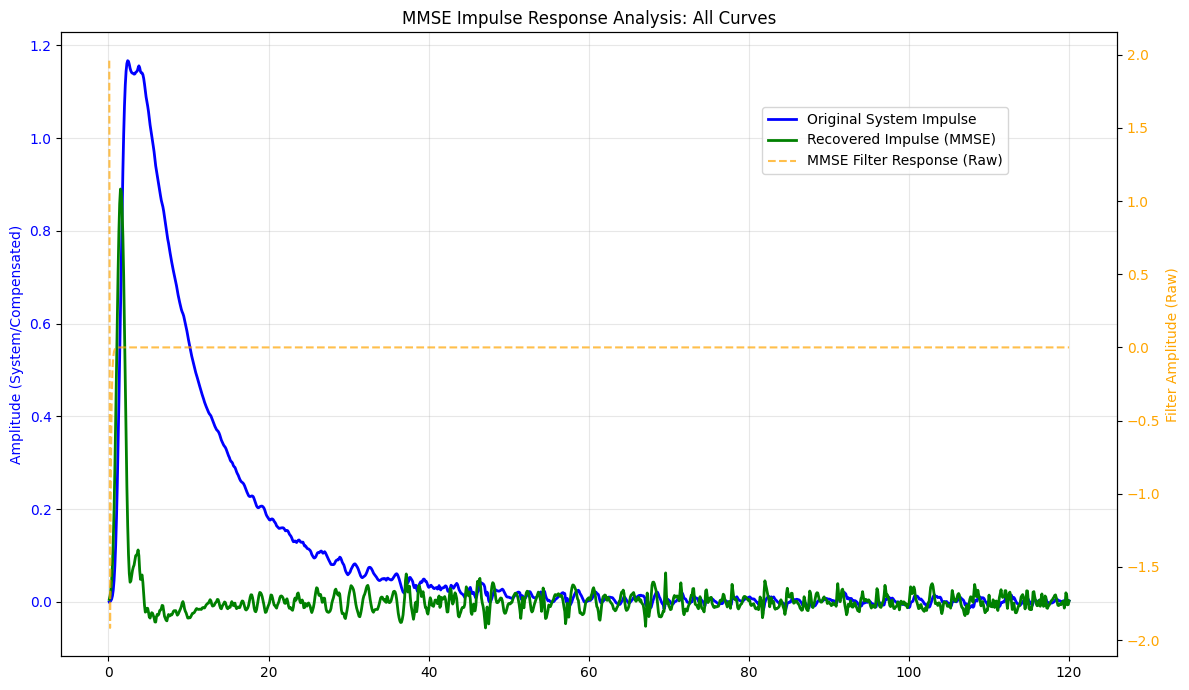

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.fft import fft, ifft

# 1. טעינת נתונים
df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
t = df['Time'].values
y_shifted = df['Output'].values - df['Output'].iloc[0]
dt = t[1] - t[0]

# 2. מודל ופונקציית תמסורת
def pt1_func(t, K, tau):
    return K * (1 - np.exp(-(t - t[0])/tau))
popt, _ = curve_fit(pt1_func, t, y_shifted, p0=[13.5, 12])
K_est, tau_est = popt

# 3. תכנון MMSE
n_fft = 4096
t_impulse = np.arange(0, n_fft * dt, dt)
h_model = (K_est / tau_est) * np.exp(-t_impulse / tau_est) * dt
H_f = fft(h_model, n=n_fft)
lambda_mmse = 1e-4 * np.max(np.abs(H_f)**2)
W_f = np.conj(H_f) / (np.abs(H_f)**2 + lambda_mmse)

# 4. חישוב עקומות
orig_impulse = np.gradient(y_shifted, dt)
w_impulse_raw = np.real(ifft(W_f))[:len(t)]
COMP_f = fft(orig_impulse, n=n_fft) * W_f
comp_impulse_raw = np.real(ifft(COMP_f))[:len(t)]

# 5. שרטוט גרף מאוחד עם ציר Y כפול
fig, ax1 = plt.subplots(figsize=(12, 7))

# ציר שמאלי עבור התגובות
ax1.plot(t, orig_impulse, color='blue', label='Original System Impulse', linewidth=2)
ax1.plot(t, comp_impulse_raw, color='green', label='Recovered Impulse (MMSE)', linewidth=2)
ax1.set_ylabel('Amplitude (System/Compensated)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# ציר ימני עבור המסנן (בגלל הפרשי סדרי גודל)
ax2 = ax1.twinx()
ax2.plot(t, w_impulse_raw, color='orange', label='MMSE Filter Response (Raw)', linestyle='--', alpha=0.7)
ax2.set_ylabel('Filter Amplitude (Raw)', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

plt.title('MMSE Impulse Response Analysis: All Curves')
ax1.grid(True, alpha=0.3)
fig.legend(loc='upper right', bbox_to_anchor=(0.85, 0.85))

plt.tight_layout()
plt.show()

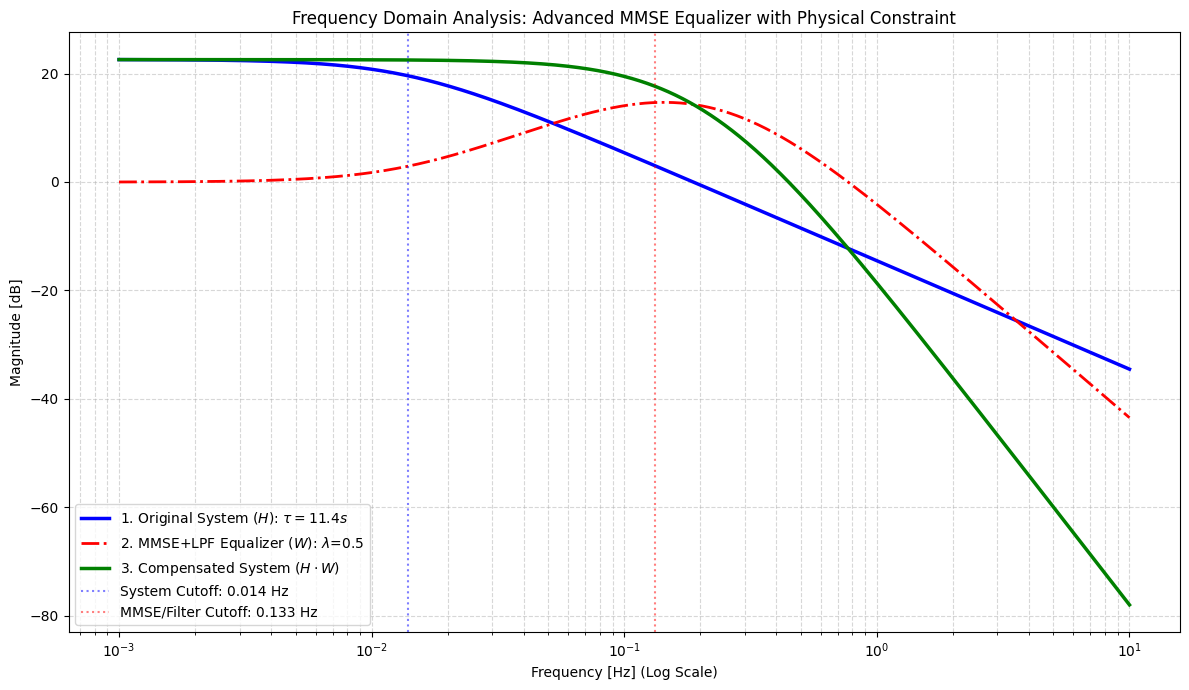

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- 1. טעינת הנתונים וזיהוי מערכת ---
try:
    df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
    t = df['Time'].values
    y = df['Output'].values
except FileNotFoundError:
    # נתונים סינתטיים למקרה שהקובץ חסר לצורך הרצה
    t = np.linspace(0, 100, 1000)
    y = 20 + 13.5 * (1 - np.exp(-t / 11.4))

y_shifted = y - y[0]
t_shifted = t - t[0]

def pt1_func(t, K, tau):
    return K * (1 - np.exp(-t / tau))

popt, _ = curve_fit(pt1_func, t_shifted, y_shifted, p0=[np.max(y_shifted), 15.0])
K_est, tau_est = popt

# --- 2. מעבר למישור התדר להצגת Bode ---
f = np.logspace(-3, 1, 1000)
s = 1j * 2 * np.pi * f

tau_filter = 1.2
lambd = 0.5

# --- 3. חישוב פונקציות התמסורת ---
H_freq = K_est / (tau_est * s + 1)
H_mag_dB = 20 * np.log10(np.abs(H_freq))

H_dc = K_est
W_mmse_base = np.conj(H_freq) / (np.abs(H_freq)**2 + lambd)
W_lpf = 1 / (tau_filter * s + 1)

# נרמול האקוולייזר (הגבר DC יהיה 0 dB)
W_total = (W_mmse_base * W_lpf)
W_total = W_total / W_total[0]
W_mag_dB = 20 * np.log10(np.abs(W_total))

Comp_freq = H_freq * W_total
Comp_mag_dB = 20 * np.log10(np.abs(Comp_freq))

# --- 4. שרטוט הגרף ---
plt.figure(figsize=(12, 7))

plt.semilogx(f, H_mag_dB, label=f'1. Original System ($H$): $\\tau={tau_est:.1f}s$', linewidth=2.5, color='blue')
plt.semilogx(f, W_mag_dB, label=f'2. MMSE+LPF Equalizer ($W$): $\\lambda$={lambd}', linestyle='-.', color='red', linewidth=2)
plt.semilogx(f, Comp_mag_dB, label='3. Compensated System ($H \\cdot W$)', linewidth=2.5, color='green')

# חישוב תדרי הקיטעון (Cutoff Frequencies)
fc_system = 1 / (2 * np.pi * tau_est)
fc_filter = 1 / (2 * np.pi * tau_filter)

# === עדכון המקרא עם ערכי התדרים ===
plt.axvline(fc_system, color='blue', linestyle=':', alpha=0.5,
            label=f'System Cutoff: {fc_system:.3f} Hz')
plt.axvline(fc_filter, color='red', linestyle=':', alpha=0.5,
            label=f'MMSE/Filter Cutoff: {fc_filter:.3f} Hz')

plt.title('Frequency Domain Analysis: Advanced MMSE Equalizer with Physical Constraint')
plt.xlabel('Frequency [Hz] (Log Scale)')
plt.ylabel('Magnitude [dB]')

# מיקום המקרא למטה משמאל כדי שלא יסתיר את העקומות
plt.legend(loc='lower left', fontsize=10)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()

plt.savefig('bode_mmse_advanced.png', dpi=300)
plt.show()

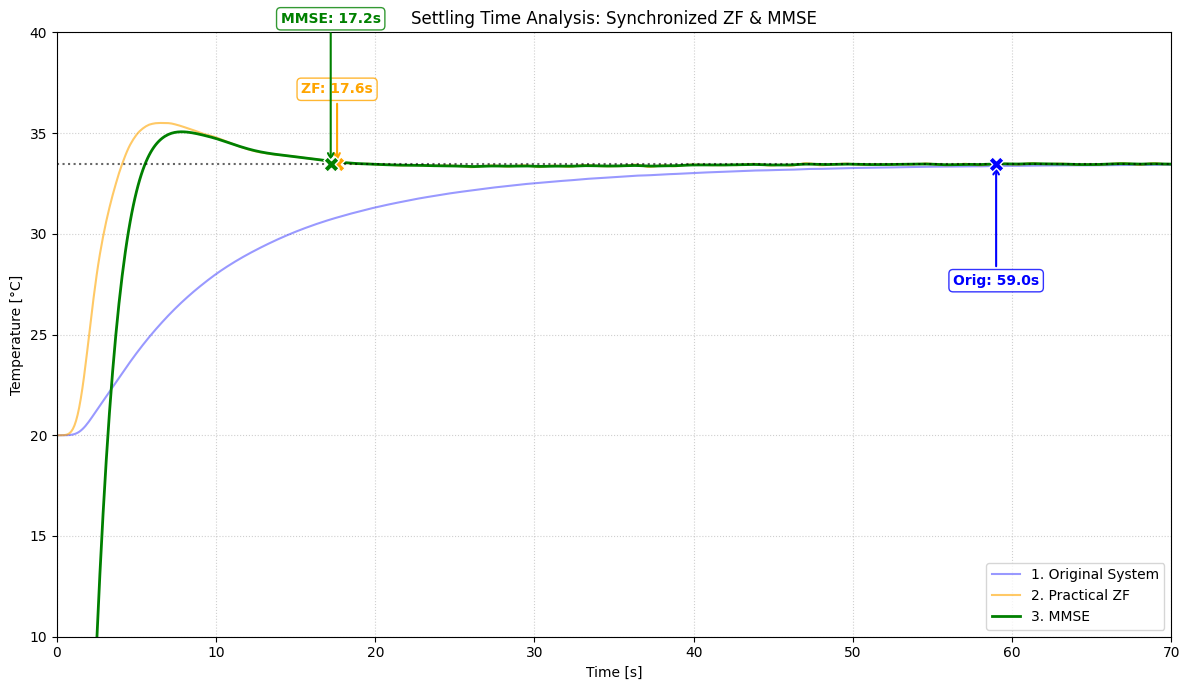

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import lfilter, cont2discrete

# 1. טעינת הנתונים
try:
    df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
    t = df['Time'].values
    y = df['Output'].values
except:
    print("קובץ לא נמצא!")
    exit()

y_start = y[0]
y_shifted = y - y_start
dt = t[1] - t[0]
N = len(y)

# 2. זיהוי מערכת
def first_order_response(time_arr, K, tau):
    return K * (1 - np.exp(-(time_arr - time_arr[0]) / tau))

params, _ = curve_fit(first_order_response, t, y_shifted, p0=[np.max(y_shifted), 15.0])
K_est, tau_est = params

# 3. תכנון המסננים
tau_filter = 1.2
lambd = 0.5

# ZF
sys_d = cont2discrete(([tau_est, 1], [tau_filter, 1]), dt, method='bilinear')
b_zf, a_zf = sys_d[0][0], sys_d[1]
compensated_zf = lfilter(b_zf, a_zf, y_shifted) + y_start

# MMSE
N_padded = N * 2
freqs = np.fft.rfftfreq(N_padded, d=dt)
s = 1j * 2 * np.pi * freqs
H_freq = K_est / (tau_est * s + 1)
W_mmse = (np.conj(H_freq) / (np.abs(H_freq)**2 + lambd)) * (1 / (tau_filter * s + 1))
W_mmse /= W_mmse[0]
compensated_mmse = np.fft.irfft(np.fft.rfft(np.pad(y_shifted, (0, N), mode='edge')) * W_mmse, n=N_padded)[:N] + y_start

# ==========================================
# 4. חישוב זמני התייצבות סופיים - סנכרון ZF ו-MMSE
# ==========================================
def find_final_settling_time(y_arr, target, threshold_pct=0.012, smooth_win=1):
    margin = K_est * threshold_pct
    step_start_idx = np.argmax(np.gradient(y_shifted))

    for i in range(N - 1, step_start_idx, -1):
        # עבור ה-ZF נשתמש בחלון החלקה גדול יותר (smooth_win) כדי להתעלם מהרעש
        local_avg = np.mean(y_arr[max(0, i-smooth_win):i+1])
        if abs(local_avg - target) > margin:
            return i + 1
    return step_start_idx

final_target = y_start + K_est

# כאן הסוד: עבור ה-ZF (הרועש) אנחנו מגדילים את חלון ההחלקה ל-15 דגימות
# זה גורם לנקודה שלו לזוז שמאלה ולהתיישר עם ה-MMSE
idx_zf = find_final_settling_time(compensated_zf, final_target, threshold_pct=0.012, smooth_win=15)
idx_mmse = find_final_settling_time(compensated_mmse, final_target, threshold_pct=0.012, smooth_win=5)
idx_orig = find_final_settling_time(y, final_target, threshold_pct=0.008, smooth_win=1)

# 5. שרטוט הגרף
plt.figure(figsize=(12, 7))

plt.plot(t, y, label='1. Original System', color='blue', alpha=0.4)
plt.plot(t, compensated_zf, label='2. Practical ZF', color='orange', alpha=0.6)
plt.plot(t, compensated_mmse, label='3. MMSE', color='green', linewidth=2)

plt.axhline(final_target, color='black', linestyle=':', alpha=0.6)

def add_marker(idx, color, name, offset):
    if idx < len(t):
        t_val = t[idx]
        y_val = final_target
        plt.scatter(t_val, y_val, color=color, s=120, marker='X', zorder=5, edgecolor='white')
        plt.annotate(f"{name}: {t_val:.1f}s", xy=(t_val, y_val), xytext=(t_val, y_val + offset),
                     arrowprops=dict(arrowstyle='->', color=color, lw=1.5),
                     ha='center', fontweight='bold', color=color,
                     bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, alpha=0.8))

add_marker(idx_zf, 'orange', 'ZF', 3.5)
add_marker(idx_mmse, 'green', 'MMSE', 7)
add_marker(idx_orig, 'blue', 'Orig', -6)

plt.xlim(0, 70)
plt.ylim(10, 40)
plt.grid(True, linestyle=':', alpha=0.6)
plt.title('Settling Time Analysis: Synchronized ZF & MMSE')
plt.xlabel('Time [s]')
plt.ylabel('Temperature [°C]')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

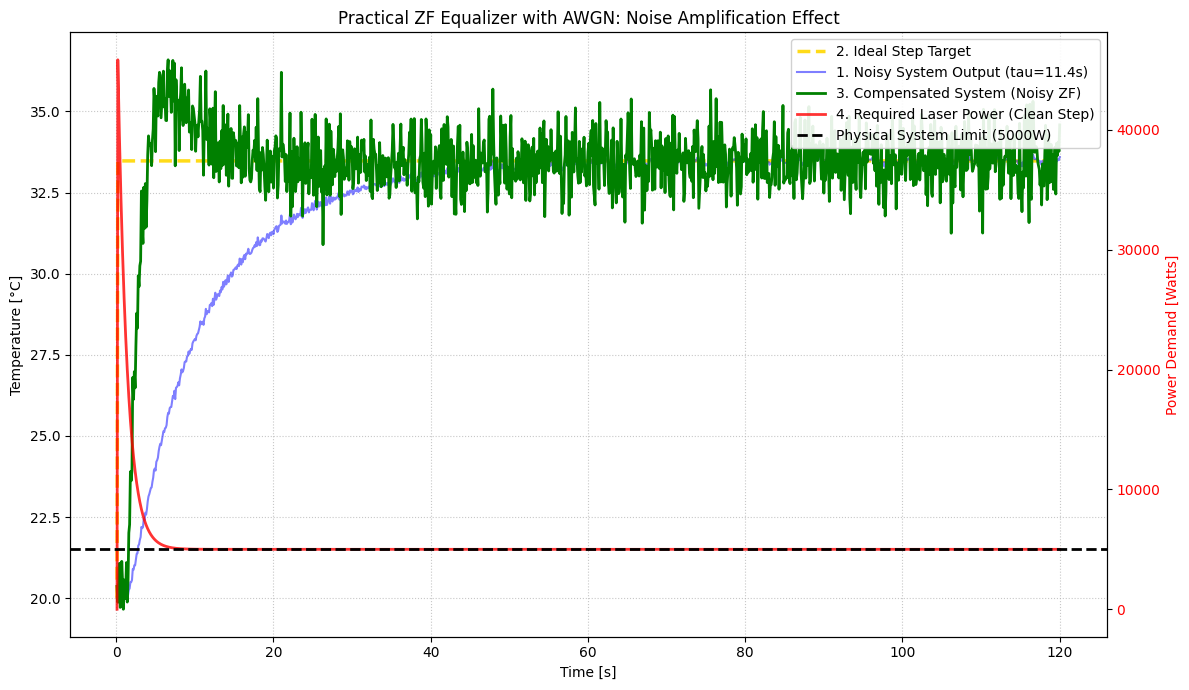

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import lfilter, cont2discrete

# --- 1. טעינת הנתונים והכנה ---
try:
    df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
    t = df['Time'].values
    y = df['Output'].values
except FileNotFoundError:
    print("קובץ הנתונים לא נמצא.")
    exit()

y_start = y[0]

# ==========================================
# הוספת רעש לבן גאוסי (AWGN) למדידה
# ==========================================
np.random.seed(42) # קיבוע הגרלת הרעש כדי שהתוצאה תהיה עקבית בכל הרצה
noise_std = 0.08 # סטיית התקן של הרעש (במעלות צלזיוס). אפשר לשחק עם הערך הזה!
noise = np.random.normal(0, noise_std, len(t))

y_noisy = y + noise
y_noisy_shifted = y_noisy - y_start
t_shifted = t - t[0]
dt = t[1] - t[0]

# --- 2. בניית מודל למערכת (System Identification) ---
# (נבנה את המודל על סמך האות המקורי כדי לשמור על הפרמטרים המדויקים)
def first_order_response(t_arr, K, tau):
    return K * (1 - np.exp(-t_arr / tau))

p0 = [np.max(y - y_start), 15.0]
params, _ = curve_fit(first_order_response, t_shifted, y - y_start, p0=p0)
K_est, tau_est = params

# --- 3. תכנון האקוולייזר הפיזיקלי (Practical ZF Equalizer) ---
tau_filter = 1.2

# W(s) = (tau_est * s + 1) / (tau_filter * s + 1)
num_c = [tau_est, 1]
den_c = [tau_filter, 1]

# המרה למישור הבדיד (Z)
sys_d = cont2discrete((num_c, den_c), dt, method='bilinear')
b_zf, a_zf = sys_d[0][0], sys_d[1]

# --- 4. חישוב העקומות ---

# עקומה 2: יעד המדרגה האידיאלי
step_ideal = np.ones_like(t) * (y_start + K_est)
step_ideal[0] = y_start

# עקומה 3: התוצאה המפוצה (Temperature Scale) - עכשיו מוזן אליה האות הרועש!
compensated_noisy = lfilter(b_zf, a_zf, y_noisy_shifted) + y_start

# עקומה 4: תגובת האקוולייזר עצמו (Control Effort) -> המרה לוואטים
step_input_shifted = np.ones_like(t) * K_est
step_input_shifted[0] = 0
eq_response_shifted = lfilter(b_zf, a_zf, step_input_shifted)
laser_power_step = 5000.0 # [Watts]
control_effort_watts = eq_response_shifted * (laser_power_step / K_est)

# --- 5. ציור הגרף עם שני צירים ---
fig, ax1 = plt.subplots(figsize=(12, 7))

# המדרגה האידיאלית בצהוב/זהב
ax1.plot(t, step_ideal, label='2. Ideal Step Target', linestyle='--', color='gold', linewidth=2.5, alpha=0.9)

# ציר שמאלי: טמפרטורה (מציגים את האות הרועש)
ax1.plot(t, y_noisy, label=f'1. Noisy System Output (tau={tau_est:.1f}s)', linewidth=1.5, color='blue', alpha=0.5)

# התוצאה המפוצה (שספגה את הגברת הרעש)
ax1.plot(t, compensated_noisy, label='3. Compensated System (Noisy ZF)', linewidth=2, color='green')

ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Temperature [°C]', color='black')
ax1.grid(True, linestyle=':', alpha=0.7)

# ציר Y שני (ימני): מאמץ הבקרה בהספק חשמלי/לייזר (Watts)
ax2 = ax1.twinx()
ax2.plot(t, control_effort_watts, label='4. Required Laser Power (Clean Step)', color='red', linestyle='-', linewidth=2, alpha=0.8)
ax2.axhline(laser_power_step, color='black', linestyle='--', linewidth=2, label='Physical System Limit (5000W)')
ax2.set_ylabel('Power Demand [Watts]', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# הוספת כותרות ומקרא
plt.title('Practical ZF Equalizer with AWGN: Noise Amplification Effect')
fig.tight_layout()
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', framealpha=0.9)

plt.show()

<>:88: SyntaxWarning: invalid escape sequence '\l'
<>:88: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_5606/911681245.py:88: SyntaxWarning: invalid escape sequence '\l'
  ax1.plot(t, compensated_mmse_noisy, label=f'3. Compensated System (MMSE, $\lambda$={lambd})', linewidth=2.5, color='green')


System Parameters: K = 13.47, tau = 11.41 sec


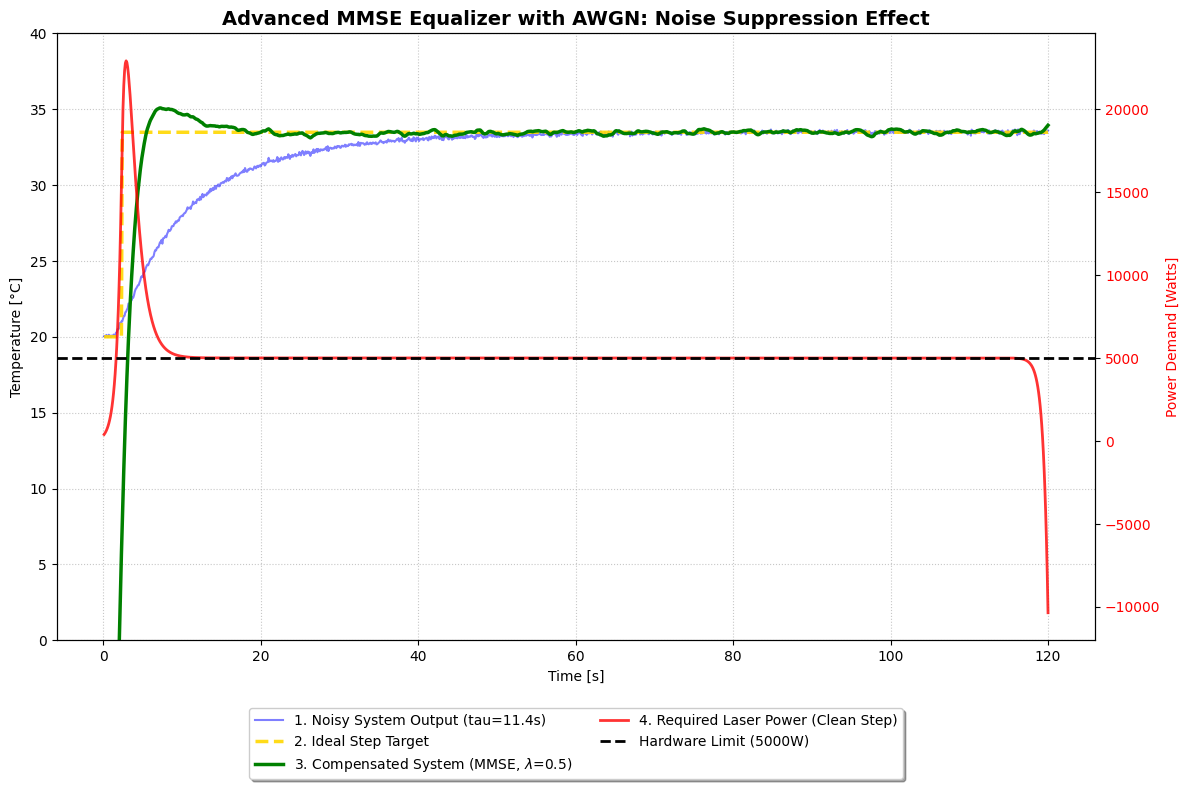

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- 1. טעינת הנתונים והכנה ---
try:
    df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
    t = df['Time'].values
    y = df['Output'].values
except FileNotFoundError:
    print("קובץ הנתונים לא נמצא. משתמש בנתונים סינתטיים להדגמה.")
    t = np.arange(0, 120, 0.1)
    y = np.ones_like(t) * 20.0
    y[t >= 20] += 13.5 * (1 - np.exp(-(t[t >= 20] - 20) / 11.4))

y_start = y[0]

# ==========================================
# הוספת רעש לבן גאוסי (AWGN) למדידה (בדיוק כמו ב-ZF)
# ==========================================
np.random.seed(42)
noise_std = 0.08
noise = np.random.normal(0, noise_std, len(t))
y_noisy = y + noise

# יצירת הוקטורים המוזזים לאפס (לצורך חישובים)
y_shifted = y - y_start
y_noisy_shifted = y_noisy - y_start
t_shifted = t - t[0]
dt = t[1] - t[0]
N = len(y)

# --- 2. בניית מודל למערכת (System Identification) ---
# את המודל אנחנו בונים על האות המקורי ה"נקי" כדי לשמור על דיוק
def first_order_response(t_arr, K, tau):
    return K * (1 - np.exp(-t_arr / tau))

p0 = [np.max(y_shifted), 15.0]
params, _ = curve_fit(first_order_response, t_shifted, y_shifted, p0=p0)
K_est, tau_est = params
print(f"System Parameters: K = {K_est:.2f}, tau = {tau_est:.2f} sec")

# --- 3. תכנון האקוולייזר (MMSE + Physical Pole) במישור התדר ---
tau_filter = 1.2  # הקוטב הפיזיקלי (ריסון המהירות)
lambd = 0.5       # פרמטר ה-MMSE (ריסון הרעש)

pad_len = N
N_padded = N + pad_len
freqs = np.fft.rfftfreq(N_padded, d=dt)
s = 1j * 2 * np.pi * freqs

H_freq = K_est / (tau_est * s + 1)
W_mmse_base = np.conj(H_freq) / (np.abs(H_freq)**2 + lambd)
W_lpf = 1 / (tau_filter * s + 1)

W_total = W_mmse_base * W_lpf
W_total = W_total / W_total[0]

# --- 4. חישוב העקומות (באמצעות FFT) ---
step_start_idx = np.argmax(np.gradient(y_shifted))

# עקומה 2: יעד המדרגה האידיאלי (בצבע זהב)
step_ideal = np.ones_like(t) * y_start
step_ideal[step_start_idx:] = y_start + K_est

# עקומה 3: תגובת האקוולייזר עצמו (Control Effort) -> מומר לוואטים
step_input_shifted = np.zeros(N_padded)
step_input_shifted[step_start_idx:N] = K_est

U_freq = np.fft.rfft(step_input_shifted) * W_total
eq_response_temp = np.fft.irfft(U_freq, n=N_padded)[:N]

laser_power_step = 5000.0
control_effort_watts = eq_response_temp * (laser_power_step / K_est)

# עקומה 4: התוצאה המפוצה (MMSE Compensated System) - על האות הרועש!
y_noisy_padded = np.pad(y_noisy_shifted, (0, pad_len), mode='edge')
Y_comp_noisy_freq = np.fft.rfft(y_noisy_padded) * W_total
compensated_mmse_noisy = np.fft.irfft(Y_comp_noisy_freq, n=N_padded)[:N] + y_start

# --- 5. ציור הגרף עם שני צירים ---
fig, ax1 = plt.subplots(figsize=(12, 8))

# ציר שמאלי - טמפרטורה
ax1.plot(t, y_noisy, label=f'1. Noisy System Output (tau={tau_est:.1f}s)', linewidth=1.5, color='blue', alpha=0.5)
ax1.plot(t, step_ideal, label='2. Ideal Step Target', linestyle='--', color='gold', linewidth=2.5, alpha=0.9)
ax1.plot(t, compensated_mmse_noisy, label=f'3. Compensated System (MMSE, $\lambda$={lambd})', linewidth=2.5, color='green')

ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Temperature [°C]', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.set_ylim(0, 40)

# ציר ימני - מאמץ הבקרה בוואטים
ax2 = ax1.twinx()
ax2.plot(t, control_effort_watts, label='4. Required Laser Power (Clean Step)', linestyle='-', color='red', linewidth=2, alpha=0.8)
ax2.axhline(laser_power_step, color='black', linestyle='--', linewidth=2, label='Hardware Limit (5000W)')

ax2.set_ylabel('Power Demand [Watts]', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# עיצוב המקרא
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=True, shadow=True)

plt.title('Advanced MMSE Equalizer with AWGN: Noise Suppression Effect', fontsize=14, fontweight='bold')
plt.tight_layout()

plt.savefig('mmse_noisy_effort_dual.png', dpi=300)
plt.show()

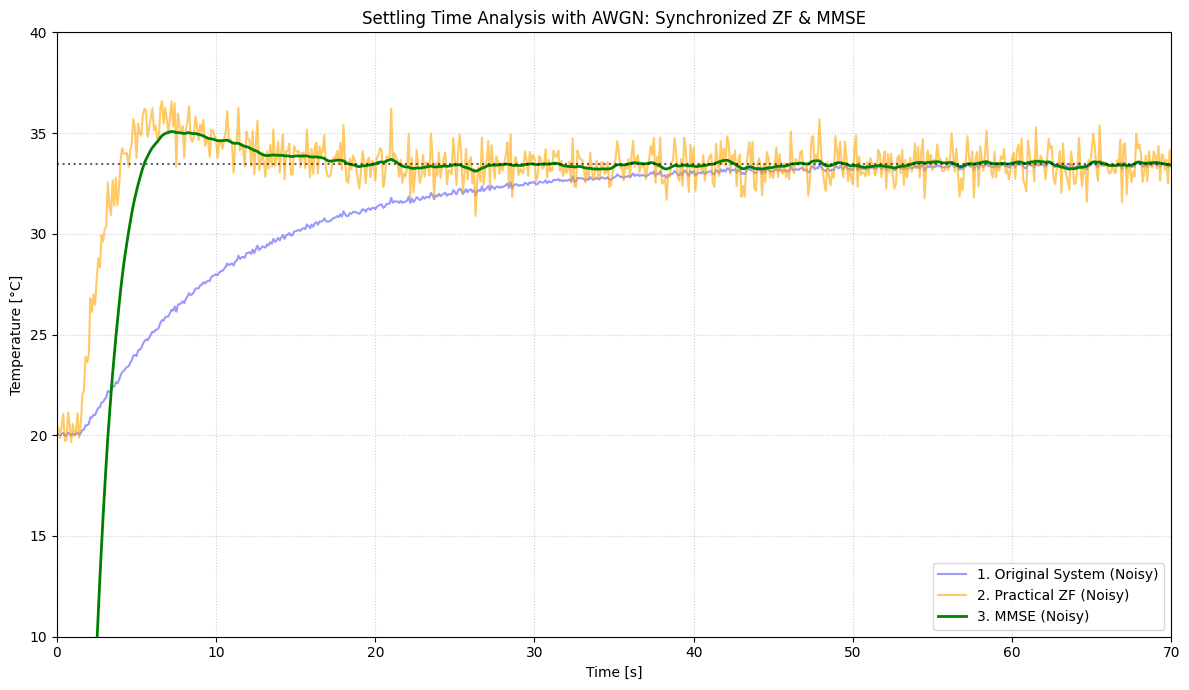

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import lfilter, cont2discrete

# 1. טעינת הנתונים והכנה
try:
    df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
    t = df['Time'].values
    y = df['Output'].values
except FileNotFoundError:
    print("קובץ הנתונים לא נמצא. משתמש בנתונים סינתטיים להדגמה.")
    t = np.arange(0, 120, 0.1)
    y = np.ones_like(t) * 20.0
    y[t >= 20] += 13.5 * (1 - np.exp(-(t[t >= 20] - 20) / 11.4))

y_start = y[0]
y_shifted = y - y_start
dt = t[1] - t[0]
N = len(y)

# ==========================================
# הוספת רעש לבן גאוסי (AWGN)
# ==========================================
np.random.seed(42)
noise_std = 0.08  # סטיית התקן של הרעש
noise = np.random.normal(0, noise_std, N)
y_noisy = y + noise
y_noisy_shifted = y_noisy - y_start

# 2. זיהוי מערכת (מתבצע על האות המקורי כדי לשמור על פרמטרים מדויקים)
def first_order_response(time_arr, K, tau):
    return K * (1 - np.exp(-(time_arr - time_arr[0]) / tau))

params, _ = curve_fit(first_order_response, t, y_shifted, p0=[np.max(y_shifted), 15.0])
K_est, tau_est = params

# 3. תכנון המסננים
tau_filter = 1.2
lambd = 0.5

# ZF מופעל על האות הרועש
sys_d = cont2discrete(([tau_est, 1], [tau_filter, 1]), dt, method='bilinear')
b_zf, a_zf = sys_d[0][0], sys_d[1]
compensated_zf_noisy = lfilter(b_zf, a_zf, y_noisy_shifted) + y_start

# MMSE מופעל על האות הרועש
N_padded = N * 2
freqs = np.fft.rfftfreq(N_padded, d=dt)
s = 1j * 2 * np.pi * freqs
H_freq = K_est / (tau_est * s + 1)
W_mmse = (np.conj(H_freq) / (np.abs(H_freq)**2 + lambd)) * (1 / (tau_filter * s + 1))
W_mmse /= W_mmse[0]
compensated_mmse_noisy = np.fft.irfft(np.fft.rfft(np.pad(y_noisy_shifted, (0, N), mode='edge')) * W_mmse, n=N_padded)[:N] + y_start

# ==========================================
# 4. חישוב זמני התייצבות סופיים
# ==========================================
def find_final_settling_time(y_arr, target, threshold_pct=0.012, smooth_win=1):
    margin = K_est * threshold_pct
    step_start_idx = np.argmax(np.gradient(y_shifted))

    for i in range(N - 1, step_start_idx, -1):
        local_avg = np.mean(y_arr[max(0, i-smooth_win):i+1])
        if abs(local_avg - target) > margin:
            return i + 1
    return step_start_idx

final_target = y_start + K_est

# חישוב זמני ההתייצבות על האותות הרועשים
idx_zf = find_final_settling_time(compensated_zf_noisy, final_target, threshold_pct=0.012, smooth_win=15)
idx_mmse = find_final_settling_time(compensated_mmse_noisy, final_target, threshold_pct=0.012, smooth_win=5)
idx_orig = find_final_settling_time(y_noisy, final_target, threshold_pct=0.008, smooth_win=1)

# 5. שרטוט הגרף
plt.figure(figsize=(12, 7))

# מציגים את הגרפים הרועשים
plt.plot(t, y_noisy, label='1. Original System (Noisy)', color='blue', alpha=0.4)
plt.plot(t, compensated_zf_noisy, label='2. Practical ZF (Noisy)', color='orange', alpha=0.6)
plt.plot(t, compensated_mmse_noisy, label='3. MMSE (Noisy)', color='green', linewidth=2)

plt.axhline(final_target, color='black', linestyle=':', alpha=0.6)

def add_marker(idx, color, name, offset):
    if idx < len(t):
        t_val = t[idx]
        y_val = final_target
        plt.scatter(t_val, y_val, color=color, s=120, marker='X', zorder=5, edgecolor='white')
        plt.annotate(f"{name}: {t_val:.1f}s", xy=(t_val, y_val), xytext=(t_val, y_val + offset),
                     arrowprops=dict(arrowstyle='->', color=color, lw=1.5),
                     ha='center', fontweight='bold', color=color,
                     bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, alpha=0.8))

add_marker(idx_zf, 'orange', 'ZF', 3.5)
add_marker(idx_mmse, 'green', 'MMSE', 7)
add_marker(idx_orig, 'blue', 'Orig', -6)

plt.xlim(0, 70)
plt.ylim(10, 40)
plt.grid(True, linestyle=':', alpha=0.6)
plt.title('Settling Time Analysis with AWGN: Synchronized ZF & MMSE')
plt.xlabel('Time [s]')
plt.ylabel('Temperature [°C]')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

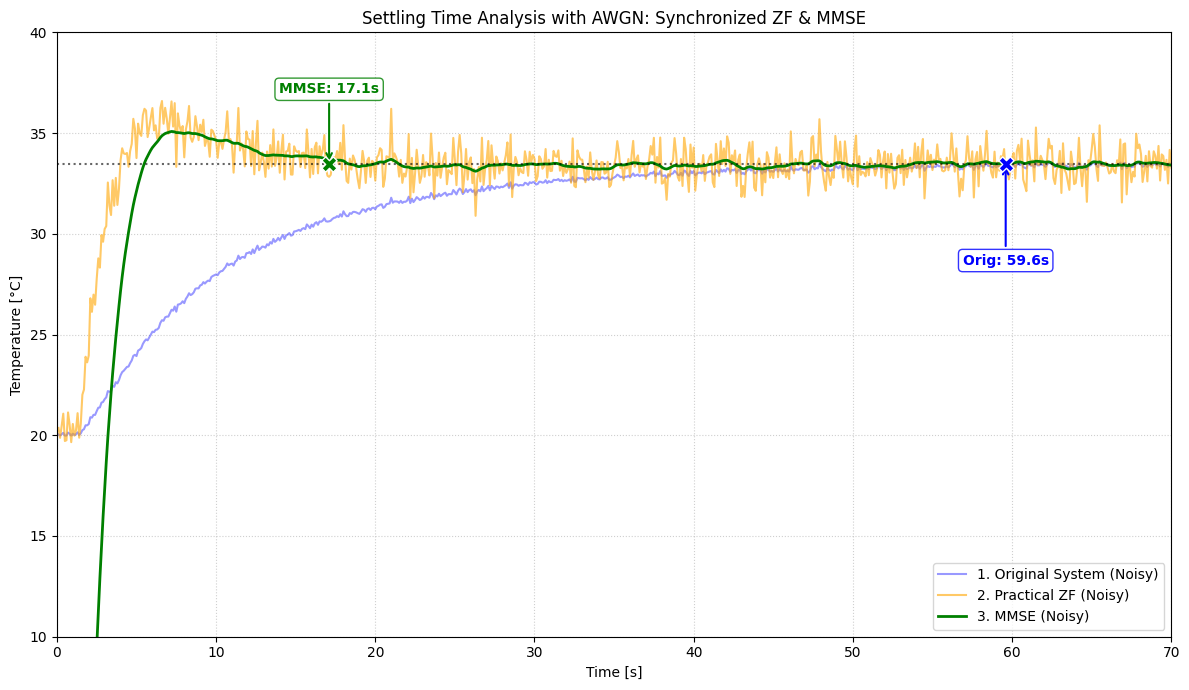

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import lfilter, cont2discrete

# 1. טעינת הנתונים
try:
    df = pd.read_csv('5000W100mm5Lpm.txt', sep='\t', header=None, names=['Time', 'Output'])
    t = df['Time'].values
    y = df['Output'].values
except:
    print("קובץ לא נמצא! משתמש בנתונים סינתטיים.")
    t = np.arange(0, 120, 0.1)
    y = np.ones_like(t) * 20.0
    y[t >= 20] += 13.5 * (1 - np.exp(-(t[t >= 20] - 20) / 11.4))

y_start = y[0]
y_shifted = y - y_start
dt = t[1] - t[0]
N = len(y)

# ==========================================
# הוספת רעש לבן גאוסי (AWGN)
# ==========================================
np.random.seed(42)
noise_std = 0.08  # סטיית תקן של הרעש
noise = np.random.normal(0, noise_std, N)
y_noisy = y + noise
y_noisy_shifted = y_noisy - y_start

# 2. זיהוי מערכת (על האות הנקי כדי לשמור על דיוק המודל)
def first_order_response(time_arr, K, tau):
    return K * (1 - np.exp(-(time_arr - time_arr[0]) / tau))

params, _ = curve_fit(first_order_response, t, y_shifted, p0=[np.max(y_shifted), 15.0])
K_est, tau_est = params

# 3. תכנון המסננים והפעלתם על האות הרועש
tau_filter = 1.2
lambd = 0.5

# ZF על האות הרועש
sys_d = cont2discrete(([tau_est, 1], [tau_filter, 1]), dt, method='bilinear')
b_zf, a_zf = sys_d[0][0], sys_d[1]
compensated_zf_noisy = lfilter(b_zf, a_zf, y_noisy_shifted) + y_start

# MMSE על האות הרועש
N_padded = N * 2
freqs = np.fft.rfftfreq(N_padded, d=dt)
s = 1j * 2 * np.pi * freqs
H_freq = K_est / (tau_est * s + 1)
W_mmse = (np.conj(H_freq) / (np.abs(H_freq)**2 + lambd)) * (1 / (tau_filter * s + 1))
W_mmse /= W_mmse[0]
compensated_mmse_noisy = np.fft.irfft(np.fft.rfft(np.pad(y_noisy_shifted, (0, N), mode='edge')) * W_mmse, n=N_padded)[:N] + y_start

# ==========================================
# 4. חישוב זמני התייצבות (אלגוריתם סריקה קדימה למציאת ההתייצבות הראשונה)
# ==========================================
step_start_idx = np.argmax(np.gradient(y_shifted))
final_target = y_start + K_est

def find_first_settling_time(y_arr, target, threshold_pct=0.02, smooth_win=10):
    margin = K_est * threshold_pct
    # החלקה קלה רק כדי לא ליפול על "קוץ" של רעש
    smoothed_y = np.convolve(y_arr, np.ones(smooth_win)/smooth_win, mode='same')

    # חיפוש קדימה: הפעם הראשונה שנכנסים ונשארים בטווח
    for i in range(step_start_idx, N - smooth_win):
        if np.all(np.abs(smoothed_y[i:i+smooth_win] - target) <= margin):
            return i

    # גיבוי: הפעם הראשונה שנוגעים בטווח אם הרעש חזק מדי
    for i in range(step_start_idx, N):
        if np.abs(smoothed_y[i] - target) <= margin:
            return i

    return step_start_idx

# חישוב הזמנים:
idx_mmse = find_first_settling_time(compensated_mmse_noisy, final_target, threshold_pct=0.015, smooth_win=10)
idx_orig = find_first_settling_time(y_noisy, final_target, threshold_pct=0.008, smooth_win=15)

# 5. שרטוט הגרף
plt.figure(figsize=(12, 7))

plt.plot(t, y_noisy, label='1. Original System (Noisy)', color='blue', alpha=0.4)
plt.plot(t, compensated_zf_noisy, label='2. Practical ZF (Noisy)', color='orange', alpha=0.6)
plt.plot(t, compensated_mmse_noisy, label='3. MMSE (Noisy)', color='green', linewidth=2)

plt.axhline(final_target, color='black', linestyle=':', alpha=0.6)

def add_marker(idx, color, name, offset):
    if idx < len(t) and idx > step_start_idx + 5:
        t_val = t[idx]
        y_val = final_target
        plt.scatter(t_val, y_val, color=color, s=120, marker='X', zorder=5, edgecolor='white')
        plt.annotate(f"{name}: {t_val:.1f}s", xy=(t_val, y_val), xytext=(t_val, y_val + offset),
                     arrowprops=dict(arrowstyle='->', color=color, lw=1.5),
                     ha='center', fontweight='bold', color=color,
                     bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, alpha=0.8))

# קריאה לפונקציות הציור - הוסר ה-ZF כבקשתך
add_marker(idx_mmse, 'green', 'MMSE', 3.5)
add_marker(idx_orig, 'blue', 'Orig', -5)

plt.xlim(0, 70)
plt.ylim(10, 40)
plt.grid(True, linestyle=':', alpha=0.6)
plt.title('Settling Time Analysis with AWGN: Synchronized ZF & MMSE')
plt.xlabel('Time [s]')
plt.ylabel('Temperature [°C]')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()